In [1]:
#Import functions in library
import time
import numpy as np
import matplotlib.pyplot as plt
import warnings
from matplotlib import MatplotlibDeprecationWarning
warnings.filterwarnings(
    "ignore",
    category=MatplotlibDeprecationWarning,
    message=(
        r"The (width|height|x|y) parameter as float "
        r"was deprecated in Matplotlib 3\.10.*"
    )
)

from scipy import integrate, stats
from mp3lib import (sample_mean_cov, is_valid_covariance, gaussian_pdf, whitening_matrix, lmmse_weights)

#Use SEED number
SEED = 1506714529 # drawn 2026-11-09, do not change
rng = np.random.default_rng(SEED)

#Generate one independent random-number generator for each step
rng_step1 = rng.spawn(1)[0]
rng_step2 = rng.spawn(1)[0]
rng_step3 = rng.spawn(1)[0]
rng_step4 = rng.spawn(1)[0]
rng_step5 = rng.spawn(1)[0]
rng_step6 = rng.spawn(1)[0]
rng_step7 = rng.spawn(1)[0]
rng_step8 = rng.spawn(1)[0]

np.set_printoptions(precision=6, suppress=True)
PROJECT_START = time.perf_counter()

## Step 1

Get the mechanics of joint, marginal, and conditional densities working
with (X, Y) Joint density 𝑓𝑋𝑌 (𝑥, 𝑦) = 𝑥 + 𝑦, 0 ≤ 𝑥 ≤ 1, 0 ≤ 𝑦 ≤ 1

Valid Densities must be nonnegative and integrate to 1

x + y ≥ 0 $\int_{0}^{1}\int_{0}^{1} (x + y) \,dy\,dx$ 

= $\int_{0}^{1} (x + {[(1^2)/2]-[(0^2)/2]}) \,dx$ 

= $\int_{0}^{1} (x + 1/2) \,dx$ 

= [(1^2)/2] + (1/2)1 - {[(0^2)/2] + (1/2)0}

= 1/2 + 1/2 = 1

Thus, the density is valid because it is nonnegative and it integrates to 1.



In [2]:
#Confirm the Density is valid numerically using a 2D quadrature
def joint_pdf_xy(x, y):
    if 0 <= x <= 1 and 0 <= y <= 1:
        return x + y
    return 0.0
joint_integral, joint_quad_error = integrate.dblquad(lambda y, x: x + y, 0, 1, lambda x: 0, lambda x: 1)
print(f"Joint-density integral = {joint_integral:.10f}")
print(f"Quadrature estimated absolute error = {joint_quad_error:.3e}")

Joint-density integral = 1.0000000000
Quadrature estimated absolute error = 1.663e-14


Derive both marginals

$ 𝑓_𝑋(𝑥) $ = $\int_{-∞}^{∞} 𝑓_{𝑋𝑌} (𝑥, 𝑦) \,dy$

$ 𝑓_𝑋(𝑥) $ = $\int_{0}^{1} (x + y) \,dy$

= [xy + (y^2)/2] y = 1 and 0

= [x(1) + (1^2)/2] - [x(0) + (0^2)/2]

$ 𝑓_𝑋(𝑥) $ = {x + 1/2, 0 ≤ 𝑥 ≤ 1
        
         0, otherwise}
$ 𝑓_𝑋(.3) $ = .3 + .5 = .8 

<br>
<br>
<br>
$ 𝑓_Y(y) $ = $\int_{0}^{1} (x + y) \,dx$

= [xy + (x^2)/2] x = 1 and 0

= [y(1) + (1^2)/2] - [y(0) + (0^2)/2]

$ 𝑓_Y(y) $ = {y + 1/2, 0 ≤ y ≤ 1

         0, otherwise}

Thus, outside [0,1] both marginal densities are 0

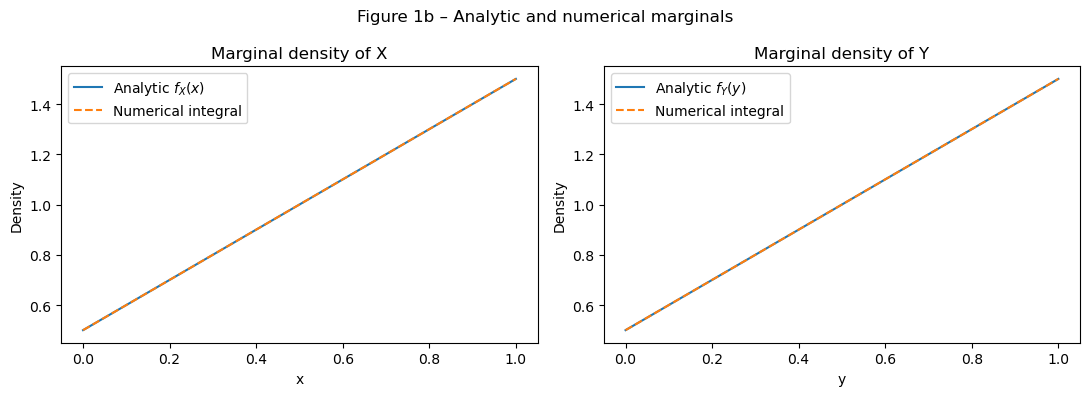

Maximum marginal-grid error: 8.881784197001252e-16


In [3]:
#Confirm numerically by integrating joint density 
grid = np.linspace(0, 1, 501)
Xg, Yg = np.meshgrid(grid, grid, indexing="xy")
Zg = Xg + Yg
fx_analytic = grid + 0.5
fy_analytic = grid + 0.5
#Integrate the joint density along the other coordinate
fx_numeric = np.trapezoid(Zg, grid, axis=0)   #integrate over y, retain x
fy_numeric = np.trapezoid(Zg, grid, axis=1)   #integrate over x, retain y
#Plot data
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(grid, fx_analytic, label="Analytic $f_X(x)$")
ax[0].plot(grid, fx_numeric, "--", label="Numerical integral")
ax[0].set(title="Marginal density of X", xlabel="x", ylabel="Density")
ax[0].legend()
ax[1].plot(grid, fy_analytic, label="Analytic $f_Y(y)$")
ax[1].plot(grid, fy_numeric, "--", label="Numerical integral")
ax[1].set(title="Marginal density of Y", xlabel="y", ylabel="Density")
ax[1].legend()
fig.suptitle("Figure 1b – Analytic and numerical marginals")
plt.tight_layout()
plt.show()
print("Maximum marginal-grid error:",
      max(np.max(np.abs(fx_numeric-fx_analytic)),
          np.max(np.abs(fy_numeric-fy_analytic))))

After integrating the joint probability denisty function 𝑓𝑋𝑌 (𝑥, 𝑦) = 𝑥 + 𝑦 over the variable that wasn't considered we obtained x + 1/2 for 0 ≤ 𝑥 ≤ 1 and y + 1/2 for 0 ≤ y ≤ 1 with 0 otherwise for both. Therefore, when x = .3, then fX(.3) = .3 + .5 = .8. Thus, one may see that both marginal densities are defined over the interval [0,1] with 0 elsewhere. To confirm the result, numerical integration was used and as we can see by the graphs that both curves closely overlap, which proves that the integration agrees with the derivations. Therefore, after calculating max marginal error, we obtained a 8.88 x 10^-16, which is small enough to demonstrate a success in our data and prove that both results are similar. After all, the small error was due to the finite spacing in the graph and the numerical integration through trapezoid. Since both graphs have an increasing linear shape, we can deduce that higher X and Y values have a higher marginal probablity density than lower values. For instance, when X is 1/2, then the marginal density is 1. Although the marginal densities describe each variable individually, the joint density describes the relationship between both variables.

Derive conditional density of Y given X = x

$\ f_{Y|X}(y|x) = \frac{f_{XY}(x,y)}{f_X(x)} = \frac{x+y}{x+1/2},\quad0\leq y\leq1 \$

At x = .3 

$\ f_{Y|X}(y|0.3) = \frac{0.3+y}{0.8},\quad0\leq y\leq1 \$

$\ \int_0^1\frac{0.3+y}{0.8}dy = \frac{0.3+0.5}{0.8} = 1 \$

It integrates to 1 because it is a conditional density.

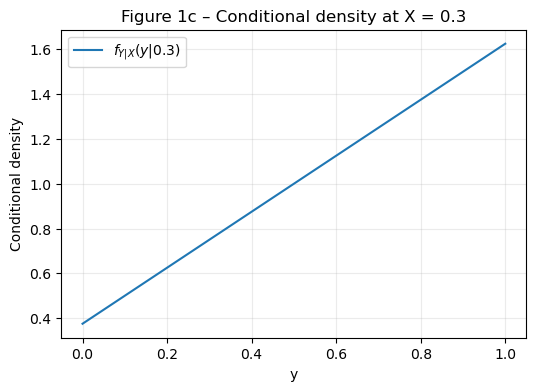

Conditional density integral = 1.00000000


In [4]:
#Plot of conditional density at x = .3
x0 = 0.3
conditional = (x0 + grid) / (x0 + 0.5)
conditional_integral = np.trapezoid(conditional, grid)
plt.figure(figsize=(6, 4))
plt.plot(grid, conditional, label=r"$f_{Y|X}(y|0.3)$")
plt.xlabel("y")
plt.ylabel("Conditional density")
plt.title("Figure 1c – Conditional density at X = 0.3")
plt.legend()
plt.grid(alpha=0.25)
plt.show()
print(f"Conditional density integral = {conditional_integral:.8f}")

The graph above is a plot of conditional density at x = .3, which indicates the relationship between X and Y given x = .3. As one can see by the graph, the conditional density increases linearly as y increases from 0 to 1, with the value starting at .375 and ending at 1.625. After the conditional density was integrated over the interval [0,1], we obtained 1, which indicates that the total area is 1. Thus, the conditional PDF is valid and shows the relationship between X and Y. 

Through symmetry E[X] = E[Y]

$\ E[X] = \int_0^1\int_0^1 x(x+y) dy dx
 = \int_0^1(x^2+x/2) dx = \frac13+\frac14 = \frac7{12} \$

$\ E[X] = \frac7{12} = .583333 \$

<br>
<br>

$\ E[Y] = \int_0^1\int_0^1 y(x+y) dx dy
 = \int_0^1(y^2+y/2) dy = \frac13+\frac14 = \frac7{12} \$

$\ E[Y] = \frac7{12} = .583333 \$

<br>
<br>

$\ E[XY] = \int_0^1\int_0^1 xy(x+y) dy dx = \int_0^1\int_0^1 (x^2y+xy^2) dx dy = \frac16+\frac16 = \frac13 \$

$\ E[XY] = \frac13 \$

<br>
<br>

$\ E[X^2] = \int_0^1\int_0^1 x^2(x+y) dy dx
 = \int_0^1(x^3+(x^2)/2) dx = \frac14+\frac16 = \frac5{12} \$

$\ Var(X) = E[X^2] - E[X]^2 = \frac5{12} - (\frac7{12})^2 = \frac{11}{144} \$

$\ Var(X) = \frac{11}{144} = .0763889 \$

<br>
<br>

$\ Cov(X,Y) = E[XY]-E[X]E[Y] = \frac13-\frac{49}{144} = -\frac1{144} \$

$\ Cov(X,Y) = -\frac1{144} = -0.00694444 \$

<br>
<br>

Correlation Coeffient

Through symmetry Var(X) = Var(Y)

$\ Var(Y) = \frac{11}{144} = .0763889 \$

$\ \rho = \frac{Cov(X,Y)}{\sqrt{(Var(X))(Var(Y))}} = \frac{-1/144}{\sqrt{(11/144)(11/144)}} = -\frac1{11} \$

$\ \rho = -\frac1{11} = -0.0909091 \$


In [5]:
EX = EY = 7/12
EXY = 1/3
varX = varY = 11/144
covXY = -1/144
rhoXY = -1/11

#Numerical quadrature of the raw moments
quad_EX = integrate.dblquad(lambda y, x: x*(x+y), 0, 1, lambda x: 0, lambda x: 1)[0]
quad_EY = integrate.dblquad(lambda y, x: y*(x+y), 0, 1, lambda x: 0, lambda x: 1)[0]
quad_EXY = integrate.dblquad(lambda y, x: x*y*(x+y), 0, 1, lambda x: 0, lambda x: 1)[0]
quad_EX2 = integrate.dblquad(lambda y, x: x*x*(x+y), 0, 1, lambda x: 0, lambda x: 1)[0]
quad_EY2 = integrate.dblquad(lambda y, x: y*y*(x+y), 0, 1, lambda x: 0, lambda x: 1)[0]
quad_varX = quad_EX2 - quad_EX**2
quad_varY = quad_EY2 - quad_EY**2
quad_cov = quad_EXY - quad_EX*quad_EY
quad_rho = quad_cov / np.sqrt(quad_varX*quad_varY)
print("Analytic: EX = EY = 7/12, EXY = 1/3, VarX = VarY = 11/144,")
print("          CovXY = -1/144, rho = -1/11")
print(f"Quadrature: EX = {quad_EX:.8f}, EY = {quad_EY:.8f}, EXY = {quad_EXY:.8f}")
print(f"            VarX = {quad_varX:.8f}, VarY = {quad_varY:.8f}")
print(f"            CovXY = {quad_cov:.8f}, rho = {quad_rho:.8f}")

Analytic: EX = EY = 7/12, EXY = 1/3, VarX = VarY = 11/144,
          CovXY = -1/144, rho = -1/11
Quadrature: EX = 0.58333333, EY = 0.58333333, EXY = 0.33333333
            VarX = 0.07638889, VarY = 0.07638889
            CovXY = -0.00694444, rho = -0.09090909


After verifying each value by quadrature, one can see that the values are similar, which proves the relationships between the X and Y values.  

Acceptance rate and bounding constant

Bounding constant M:

𝑓𝑋𝑌 (𝑥, 𝑦) = 𝑥 + 𝑦, 0 ≤ 𝑥 ≤ 1, 0 ≤ 𝑦 ≤ 1

max occurs when x = 1 and y = 1

Thus, when 𝑓𝑋𝑌 (1, 1) = 1 + 1 = 2

Therefore, M = 2

Acceptance rate: 

$\ P(accept) = \frac{1}{M}\int_0^1\int_0^1 (x+y) dy dx \$

 = $\ \frac{1}{2}\int_0^1 (x1+(1^2)/2) - [(x0+(0^2)/2)] dx \$

 = $\ \frac{1}{2}\int_0^1 (x+1/2) dx \$

 = $\ \frac{1}{2} {[(1^2)/2]+[(1/2)(1)]} \$

 = $\ \frac{1}{2} (1) \$

 = P(accept) = 1/2 = 50%


In [6]:
N1 = 1_000_000
accepted = []
n_proposed = 0
while sum(a.shape[0] for a in accepted) < N1:
    remaining = N1 - sum(a.shape[0] for a in accepted)
    batch = max(100_000, int(2.2*remaining))
    proposal = rng_step1.random((batch, 2))
    keep = rng_step1.random(batch) < proposal.sum(axis=1)/2
    accepted.append(proposal[keep])
    n_proposed += batch
samples1 = np.concatenate(accepted, axis=0)[:N1]
x1, y1 = samples1.T
n_accepted_total = sum(a.shape[0] for a in accepted)
acceptance_rate = n_accepted_total / n_proposed

#call mean_se function to calculate standard error
def mean_se(a):
    return np.std(a, ddof=1) / np.sqrt(a.size)
mX, mY = x1.mean(), y1.mean()
mXY = (x1*y1).mean()
vX, vY = x1.var(ddof=1), y1.var(ddof=1)
cXY = np.cov(x1, y1, ddof=1)[0, 1]

#Influence values for variance and covariance estimators
ifx = (x1-mX)**2 - vX
ify = (y1-mY)**2 - vY
ifcov = (x1-mX)*(y1-mY) - cXY
print(f"Accepted N={N1:,}; proposals={n_proposed:,}; acceptance={acceptance_rate:.4f}")
print("Statistic   estimate    theory    difference  estimated SE")
rows = [("E[X]", mX, EX, mX-EX, mean_se(x1)),
    ("E[Y]", mY, EY, mY-EY, mean_se(y1)),
    ("E[XY]", mXY, EXY, mXY-EXY, mean_se(x1*y1)),
    ("Var(X)", vX, varX, vX-varX, mean_se(ifx)),
    ("Var(Y)", vY, varY, vY-varY, mean_se(ify)),
    ("Cov(X,Y)", cXY, covXY, cXY-covXY, mean_se(ifcov)),]
for name, est, theory, diff, se in rows:
    print(f"{name:10s} {est: .7f}  {theory: .7f}  {diff: .3e}  {se:.3e}")
#Calculate sample correlation
rho_sample = np.corrcoef(x1, y1)[0, 1]
#Calculate difference from theoretical correlation
rho_difference = rho_sample - rhoXY
rho_abs_difference = abs(rho_difference)
#Center the samples
x_centered = x1 - x1.mean()
y_centered = y1 - y1.mean()
#Standardize the samples
u = x_centered / np.std(x1, ddof=1)
v = y_centered / np.std(y1, ddof=1)
#Calculate influence values for correlation
ifrho = u*v - (rho_sample/2)*(u**2 + v**2)
#Estimate standard error
se_rho = np.std(ifrho, ddof=1) / np.sqrt(N1)
print("\nCorrelation statistics:")
print(f"Sample correlation:       {rho_sample:.8f}")
print(f"Theoretical correlation:  {rhoXY:.8f}")
print(f"Absolute difference:      {rho_abs_difference:.3e}")
print(f"Estimated standard error: {se_rho:.3e}")

Accepted N=1,000,000; proposals=2,200,000; acceptance=0.4998
Statistic   estimate    theory    difference  estimated SE
E[X]        0.5835585   0.5833333   2.252e-04  2.763e-04
E[Y]        0.5836628   0.5833333   3.294e-04  2.762e-04
E[XY]       0.3337121   0.3333333   3.787e-04  2.357e-04
Var(X)      0.0763605   0.0763889  -2.842e-05  7.642e-05
Var(Y)      0.0762715   0.0763889  -1.174e-04  7.622e-05
Cov(X,Y)   -0.0068893  -0.0069444   5.515e-05  7.472e-05

Correlation statistics:
Sample correlation:       -0.09027327
Theoretical correlation:  -0.09090909
Absolute difference:      6.358e-04
Estimated standard error: 9.708e-04


After generating 10^6 samples from the joint density we obtained an acceptance rate of around .49, which was expected because the theoretical acceptance rate was .5 or 50% of the samples. After all, from the 2,200,000 proposals, only 1,000,000 were accepted. To obtain the bounding constant of 2, we used the max value of the joint PDF 𝑓𝑋𝑌 (𝑥, 𝑦) = 𝑥 + 𝑦, which was x = 1 and y = 1. That gave us the value 2, which was our bounding constant. Therefore, during rejection sampling, the points were generated uniformly and were accepted uniformly when the random number was less than or equal to (x + y)/2. As far as the rest of the statistics go, we were able to notice that the values were similar between the theoretical and experimental with 10^6 samples with a small standard error, which was acceptable because of how closely related the values were to each other. After all, for the Cov(X,Y), the theoretical value was -0.0069444 with and experimental value being -0.0069092 for 10^6 samples and a standard error of 7.471e-05. In conclusion, the small standard error was due to the different number of values of the samples that were taken in the experiment.

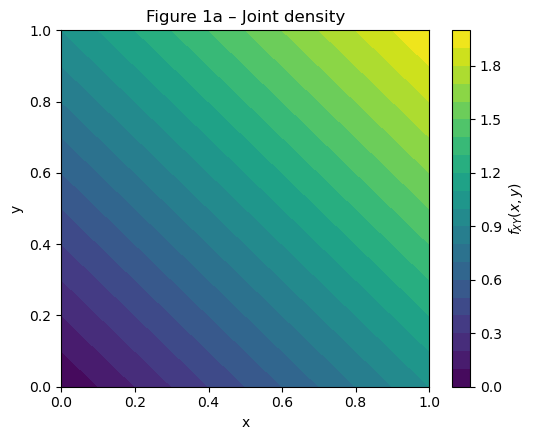

In [7]:
#plot Joint Density
fig, ax = plt.subplots(figsize=(5.5, 4.5))
cont = ax.contourf(Xg, Yg, Zg, levels=20, cmap="viridis")
fig.colorbar(cont, ax=ax, label=r"$f_{XY}(x,y)$")
ax.set(xlabel="x", ylabel="y", title="Figure 1a – Joint density")
plt.tight_layout()
plt.show()

The figure 1a shows joint PDF of X and Y over the unit square where both variables range from 0 to 1 with the denisty increasing linearly in both directions. The lowest density occurs at (0,0) and the highest occurs at (1,1)  with a density of 2. Thus, the intensity becomes hogher toward the upper right corner, which indicates the combination of large values for both variables. Therefore, the joint density shows symmetry across the diagonal x=y with the color intensity representing the value of the joint density.

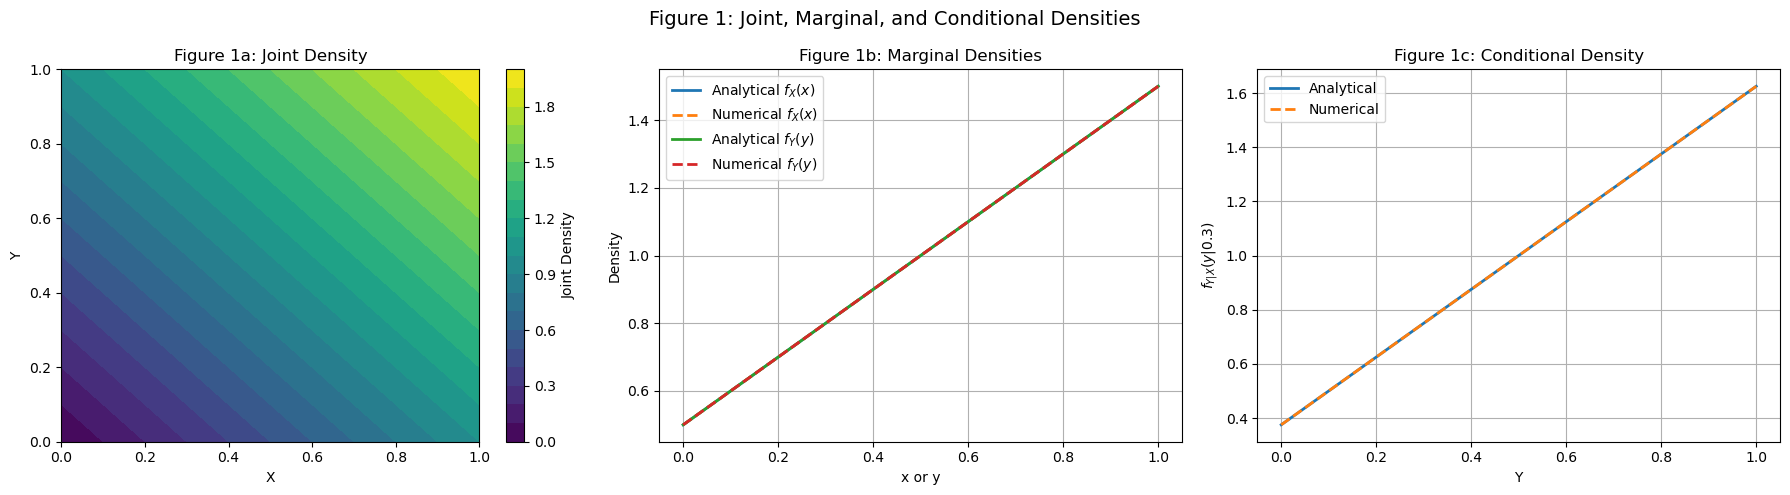

Figure 1 Numerical Verification
--------------------------------
Numerical integral of conditional density: 1.000000
Analytical integral of conditional density: 1.000000
f_X(0.3) analytical: 0.800000
f_X(0.3) numerical: 0.800000


In [8]:
import numpy as np
import matplotlib.pyplot as plt

#STEP 1: FIGURE 1 - THREE PANELS
#Create a grid over the unit square
x = np.linspace(0, 1, 201)
y = np.linspace(0, 1, 201)
X, Y = np.meshgrid(x, y)
#Joint probability density function
f_xy = X + Y
#Numerical marginal densities using trapezoidal integration
#Integrate over y to obtain f_X(x)
f_x_numerical = np.trapezoid(f_xy, y, axis=0)
#Integrate over x to obtain f_Y(y)
f_y_numerical = np.trapezoid(f_xy, x, axis=1)
#Analytical marginal densities
f_x_analytical = x + 0.5
f_y_analytical = y + 0.5

x_given = 0.3
#Analytical conditional density
f_y_given_x = (x_given + y) / (x_given + 0.5)
#Numerical conditional density using numerical marginal
f_y_given_x_numerical = (x_given + y) / np.trapezoid(x_given + y, y)
#Verify conditional density integrates to 1
conditional_integral = np.trapezoid(f_y_given_x, y)

#CREATE THREE-PANEL FIGURE
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#FIGURE 1A: JOINT DENSITY
contour = axes[0].contourf(X, Y, f_xy, levels=20, cmap="viridis")
fig.colorbar(contour, ax=axes[0], label="Joint Density")
axes[0].set_title("Figure 1a: Joint Density")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")

#FIGURE 1B: MARGINALS
#Analytical and numerical marginal of X
axes[1].plot(x, f_x_analytical, label="Analytical $f_X(x)$", linewidth=2)
axes[1].plot(x, f_x_numerical, "--", label="Numerical $f_X(x)$", linewidth=2)

#Analytical and numerical marginal of Y
axes[1].plot(y, f_y_analytical, label="Analytical $f_Y(y)$", linewidth=2)
axes[1].plot(y, f_y_numerical, "--", label="Numerical $f_Y(y)$", linewidth=2)
axes[1].set_title("Figure 1b: Marginal Densities")
axes[1].set_xlabel("x or y")
axes[1].set_ylabel("Density")
axes[1].legend()
axes[1].grid(True)

#FIGURE 1C: CONDITIONAL
axes[2].plot(y, f_y_given_x, label="Analytical", linewidth=2)
axes[2].plot(y, f_y_given_x_numerical, "--", label="Numerical", linewidth=2)
axes[2].set_title("Figure 1c: Conditional Density")
axes[2].set_xlabel("Y")
axes[2].set_ylabel(r"$f_{Y|X}(y|0.3)$")
axes[2].legend()
axes[2].grid(True)

#Overall figure title
fig.suptitle("Figure 1: Joint, Marginal, and Conditional Densities", fontsize=14)
plt.tight_layout()
plt.show()
print("Figure 1 Numerical Verification")
print("--------------------------------")
print(f"Numerical integral of conditional density: "
      f"{conditional_integral:.6f}")
print(f"Analytical integral of conditional density: 1.000000")
print(f"f_X(0.3) analytical: {0.3 + 0.5:.6f}")
print(f"f_X(0.3) numerical: "
      f"{np.interp(0.3, x, f_x_numerical):.6f}")

The following is all plots that were determined before next to each other with some verifications to show that are expected values were correct. Therefore, they show the Joint, Marginal, and Conditional Densities that were calculated and explained before in the previous cells. In the joint density figure, the color intensity represents the joint density, in the marginal density figure, both f_X(x) and f_Y(y) overlap, which indicates their individual similarities, and in the conditional density figure, the density increases linearly from .375 to 1.625 over the interval [0,1]

The correlation is small and negative, which makes X and Y pull against each other because the joint density f_X,Y(x,y) = x+y increases as either X or Y increases, but gives more weight when one variable is high while the other is low, which is seen in the top right corner of the joint density shape. Therefore, this is expected because the effects of the variables are independent, which causes a weak tendency for the variables to move in opposite directions and a weak negative linear relationship that results in a negative correlation of ρ = -1/11 = -0.0909.

## Step 2

## Step 3

For the random vector

$$
\mathbf{X}=
\begin{bmatrix}
X_1 & X_2 & X_3 & X_4
\end{bmatrix}^{T},
$$

the mean vector is

$$
\boldsymbol{\mu}=E[\mathbf{X}].
$$

$$
\Sigma_{ij}
=
\operatorname{Cov}(X_i,X_j)
=
E[(X_i-\mu_i)(X_j-\mu_j)]
=
E[X_iX_j]-\mu_i\mu_j.
$$

Therefore, the covariance matrix is

$$
\Sigma
=
E\left[
(\mathbf{X}-\boldsymbol{\mu})
(\mathbf{X}-\boldsymbol{\mu})^T
\right].
$$

In this step,

$$
\Sigma=
\begin{bmatrix}
4&2&1&0\\
2&5&2&1\\
1&2&3&1\\
0&1&1&2
\end{bmatrix}.
$$

#### 3.1 Check whether the covariance matrix is valid 
A covariance matrix must be symmetric:

$$
\Sigma=\Sigma^T,
$$

and positive semidefinite:

$$
\mathbf{a}^T\Sigma\mathbf{a}\geq 0
$$

for every vector $\mathbf{a}$.

This follows because

$$
\mathbf{a}^T\Sigma\mathbf{a}
=
\operatorname{Var}(\mathbf{a}^T\mathbf{X})
\geq 0.
$$

For a real symmetric matrix, positive semidefiniteness is equivalent to all eigenvalues being nonnegative.

I use `np.linalg.eigh`, which is designed for real symmetric matrices.
I also test the library function on a non-symmetric matrix and a symmetric matrix with a negative eigenvalue. A singular positive semidefinite matrix is still a valid covariance matrix, so we include that case as an additional check.

In [9]:
step3_start = time.perf_counter()

Sigma3 = np.array([
    [4, 2, 1, 0],
    [2, 5, 2, 1],
    [1, 2, 3, 1],
    [0, 1, 1, 2]
], dtype=float)

mu3 = np.zeros(4)
d3 = Sigma3.shape[0]

eigenvalues3, eigenvectors3 = np.linalg.eigh(Sigma3)
determinant3 = np.linalg.det(Sigma3)

nonsymmetric3 = Sigma3.copy()
nonsymmetric3[0, 1] = 3.0

negative3 = np.diag([1.0, 2.0, 3.0, -1.0])
singular3 = np.diag([1.0, 2.0, 3.0, 0.0])

for name3, matrix3, expected3 in [
    ("Project Sigma", Sigma3, True),
    ("Non-symmetric matrix", nonsymmetric3, False),
    ("Negative eigenvalue", negative3, False),
    ("Singular PSD matrix", singular3, True)
]:
    result3 = is_valid_covariance(matrix3)
    print(f"{name3:24s}: {result3} (expected {expected3})")
    assert result3 == expected3

print("\nEigenvalues:", eigenvalues3)
print(f"Determinant: {determinant3:.12f}")
print(
    f"Symmetry residual: "
    f"{np.linalg.norm(Sigma3-Sigma3.T, 'fro'):.3e}"
)
print(f"Smallest eigenvalue: {eigenvalues3[0]:.8f}")
print(
    "All eigenvalues are positive: "
    "Sigma is positive definite, hence PSD."
)

near_psd3 = np.diag([1.0, -5e-11])

assert is_valid_covariance(near_psd3, tol=1e-10)
assert not is_valid_covariance(near_psd3, tol=0.0)

# Check the group library against NumPy's unbiased covariance.
test_data3 = np.array([
    [1., 2.],
    [2., 0.],
    [4., 3.],
    [5., 1.]
])

test_mean3, test_cov3 = sample_mean_cov(test_data3)

mean_difference3 = np.max(
    np.abs(test_mean3-test_data3.mean(axis=0))
)

cov_difference3 = np.max(
    np.abs(
        test_cov3
        - np.cov(test_data3, rowvar=False, ddof=1)
    )
)

print(
    f"Library mean check, max absolute difference: "
    f"{mean_difference3:.3e}"
)

print(
    f"Library covariance check, max absolute difference: "
    f"{cov_difference3:.3e}"
)

np.testing.assert_allclose(
    test_cov3,
    np.cov(test_data3, rowvar=False, ddof=1)
)

Project Sigma           : True (expected True)
Non-symmetric matrix    : False (expected False)
Negative eigenvalue     : False (expected False)
Singular PSD matrix     : True (expected True)

Eigenvalues: [1.26487889 1.78819531 3.09808432 7.84884147]
Determinant: 55.000000000000
Symmetry residual: 0.000e+00
Smallest eigenvalue: 1.26487889
All eigenvalues are positive: Sigma is positive definite, hence PSD.
Library mean check, max absolute difference: 0.000e+00
Library covariance check, max absolute difference: 4.441e-16


#### 3.2 Generate samples with the specified covariance

I choose a zero mean because this step specifies the covariance but does not require a particular mean:

$$
\mathbf{X}\sim\mathcal{N}(\mathbf{0},\Sigma).
$$

Each row of the generated data matrix contains one independent four-dimensional observation. Thus, the data matrix has shape
$(N,4)$.

I use the existing `rng_step3` generator. 

#### 3.3 Sample mean and unbiased sample covariance

For $N$ independent observations, the sample mean is

$$
\widehat{\boldsymbol{\mu}}
=
\frac{1}{N}
\sum_{n=1}^{N}\mathbf{x}_n.
$$

The unbiased sample covariance is

$$
\widehat{\Sigma}
=
\frac{1}{N-1}
\sum_{n=1}^{N}
(\mathbf{x}_n-\widehat{\boldsymbol{\mu}})
(\mathbf{x}_n-\widehat{\boldsymbol{\mu}})^T.
$$

I divide by $N-1$ because the mean is estimated from the same data.

The `sample_mean_cov()` library function implements these formulas.

To quantify the estimation error, I use the Frobenius norm:

$$
e_N
=
\|\widehat{\Sigma}-\Sigma\|_F
=
\sqrt{
\sum_{i=1}^{4}\sum_{j=1}^{4}
(\widehat{\Sigma}_{ij}-\Sigma_{ij})^2
}.
$$

I first calculate one estimate at each required sample size.

For independent Gaussian observations, the standard errors are

$$
\operatorname{SE}(\widehat{\mu}_i)
=
\sqrt{\frac{\Sigma_{ii}}{N}},
$$

and

$$
\operatorname{SE}(\widehat{\Sigma}_{ij})
=
\sqrt{
\frac{\Sigma_{ij}^{2}+\Sigma_{ii}\Sigma_{jj}}
{N-1}
}.
$$

These allow me to compare the estimated mean and covariance entries with theoretical values.

In [10]:
N_values3 = np.array([100, 1_000, 10_000, 100_000, 1_000_000])

single_errors3 = np.empty(N_values3.size)
single_means3 = np.empty((N_values3.size, d3))
single_covariances3 = np.empty((N_values3.size, d3, d3))

for j3, N3 in enumerate(N_values3):

# Use the existing Step 3 generator.
    samples3 = rng_step3.multivariate_normal(
        mu3,
        Sigma3,
        size=int(N3),
        method="cholesky"
    )

    mean_hat3, cov_hat3 = sample_mean_cov(samples3)

    single_means3[j3] = mean_hat3
    single_covariances3[j3] = cov_hat3

    single_errors3[j3] = np.linalg.norm(cov_hat3-Sigma3, ord="fro")

# Retain the estimates without keeping every sample array.
    del samples3

print(
    f"{'N':>10} "
    f"{'Single-draw Frobenius error':>30}"
)

for N3, error3 in zip(N_values3, single_errors3):
    print(f"{N3:10d} {error3:30.8f}")

N_last3 = int(N_values3[-1])

mean_se3 = np.sqrt(np.diag(Sigma3)/N_last3)

cov_se3 = np.sqrt((Sigma3**2 + np.outer(np.diag(Sigma3), np.diag(Sigma3))) / (N_last3-1))

print(f"\nAt N = {N_last3:,}:")

print("Estimated mean:", single_means3[-1])
print("Mean minus theory:", single_means3[-1]-mu3)
print("Standard errors of mean components:", mean_se3)

print(
    "\nEstimated covariance:\n",
    single_covariances3[-1]
)

print(
    "\nCovariance minus theory:\n",
    single_covariances3[-1]-Sigma3
)

print(
    "\nStandard errors of covariance entries:\n",
    cov_se3
)

         N    Single-draw Frobenius error
       100                     0.95661277
      1000                     0.48011166
     10000                     0.26120002
    100000                     0.05185784
   1000000                     0.02591209

At N = 1,000,000:
Estimated mean: [-1.77681898e-03 -1.70277018e-05 -1.67511045e-03 -2.43410279e-06]
Mean minus theory: [-1.77681898e-03 -1.70277018e-05 -1.67511045e-03 -2.43410279e-06]
Standard errors of mean components: [0.002      0.00223607 0.00173205 0.00141421]

Estimated covariance:
 [[ 4.00298031e+00  1.99740157e+00  9.98592309e-01 -2.50475631e-03]
 [ 1.99740157e+00  4.98573691e+00  1.99000475e+00  9.92834628e-01]
 [ 9.98592309e-01  1.99000475e+00  2.99241178e+00  9.94428911e-01]
 [-2.50475631e-03  9.92834628e-01  9.94428911e-01  1.99736305e+00]]

Covariance minus theory:
 [[ 0.00298031 -0.00259843 -0.00140769 -0.00250476]
 [-0.00259843 -0.01426309 -0.00999525 -0.00716537]
 [-0.00140769 -0.00999525 -0.00758822 -0.00557109]
 [-0.00

#### 3.4 Repeat the experiment to measure the convergence rate

A single covariance estimate fluctuates randomly. Therefore, a single-draw curve is not reliable enough to fit the convergence rate.

For each sample size $N$, I generate $R$ independent datasets and calculate the error for each dataset:

$$
e_{N,r}
=
\|\widehat{\Sigma}_{N,r}-\Sigma\|_F.
$$

I average the errors themselves:

$$
\overline{e}_N
=
\frac{1}{R}
\sum_{r=1}^{R}e_{N,r}.
$$

This differs from averaging covariance matrices first and then calculating one error.

I use the required repetition counts:

| $N$ | Repetitions $R$ |
|---:|---:|
| $10^2$ | 200 |
| $10^3$ | 200 |
| $10^4$ | 100 |
| $10^5$ | 30 |
| $10^6$ | 10 |

The standard error of the averaged error is

$$
\operatorname{SE}(\overline{e}_N)
=
\frac{s_e}{\sqrt{R}},
$$

where $s_e$ is the sample standard deviation of the errors across repetitions.

The expected convergence rate is

$$
\overline{e}_N\approx C N^{-1/2}.
$$

Taking logarithms gives

$$
\log(\overline{e}_N)
\approx
\log C-\frac{1}{2}\log N.
$$

Therefore, a log-log fit should have slope approximately $-1/2$.

I also calculate

$$
\sqrt{N}\,\overline{e}_N,
$$

which should remain roughly constant if the measured rate is
$N^{-1/2}$.

In [11]:
repetitions3 = np.array([200, 200, 100, 30, 10])

mean_errors3 = np.empty(N_values3.size)
sd_errors3 = np.empty(N_values3.size)
se_errors3 = np.empty(N_values3.size)

all_errors3 = []

for j3, (N3, R3) in enumerate(
    zip(N_values3, repetitions3)
):

    errors3 = np.empty(int(R3))

    for r3 in range(int(R3)):

        samples3 = rng_step3.multivariate_normal(
            mu3,
            Sigma3,
            size=int(N3),
            method="cholesky"
        )

        _, cov_hat3 = sample_mean_cov(samples3)

        errors3[r3] = np.linalg.norm(
            cov_hat3-Sigma3,
            ord="fro"
        )

        del samples3

    all_errors3.append(errors3)

    mean_errors3[j3] = errors3.mean()
    sd_errors3[j3] = errors3.std(ddof=1)

    se_errors3[j3] = (sd_errors3[j3]/np.sqrt(R3))

scaled_errors3 = np.sqrt(N_values3)*mean_errors3
scaled_se3 = np.sqrt(N_values3)*se_errors3

relative_errors3 = (mean_errors3 / np.linalg.norm(Sigma3, ord="fro"))

slope3, log_intercept3 = np.polyfit(
    np.log(N_values3),
    np.log(mean_errors3),
    1
)

fitted_errors3 = (np.exp(log_intercept3) * N_values3**slope3)

print(
    f"{'N':>10} {'R':>5} "
    f"{'Single error':>14} {'Mean error':>14} "
    f"{'SE of mean':>14} {'sqrt(N)*mean':>15} "
    f"{'Scaled SE':>12}"
)

for j3, N3 in enumerate(N_values3):

    print(
        f"{N3:10d} "
        f"{repetitions3[j3]:5d} "
        f"{single_errors3[j3]:14.7f} "
        f"{mean_errors3[j3]:14.7f} "
        f"{se_errors3[j3]:14.7f} "
        f"{scaled_errors3[j3]:15.7f} "
        f"{scaled_se3[j3]:12.7f}"
    )

print(
    f"\nFitted log-log slope: {slope3:.6f}; "
    f"expected: -0.500000"
)

print(
    f"Measured error law: "
    f"approximately N^({slope3:.4f})"
)

print(
    f"Drop per tenfold increase in N, from the fit: "
    f"{10**(-slope3):.4f}"
)

print(
    f"Theoretical drop per decade: "
    f"{np.sqrt(10):.4f}"
)

print(
    f"Scaled-error range: "
    f"{scaled_errors3.min():.4f} "
    f"to {scaled_errors3.max():.4f}"
)

# Approximate handout checks
handout_errors3 = np.array([
    1.56, 0.49, 0.16, 0.046, 0.016
])

print("\nComparison with the handout's approximate averaged errors:")

for N3, measured3, approximate3, se3 in zip(
    N_values3,
    mean_errors3,
    handout_errors3,
    se_errors3
):

    print(
        f"N={N3:7d}: "
        f"measured={measured3:.7f}, "
        f"SE={se3:.7f}, "
        f"handout~{approximate3:.3f}, "
        f"difference={measured3-approximate3:+.7f}"
    )

         N     R   Single error     Mean error     SE of mean    sqrt(N)*mean    Scaled SE
       100   200      0.9566128      1.5427287      0.0369113      15.4272869    0.3691131
      1000   200      0.4801117      0.5083140      0.0126519      16.0743015    0.4000869
     10000   100      0.2612000      0.1499039      0.0054185      14.9903909    0.5418529
    100000    30      0.0518578      0.0530100      0.0032044      16.7632345    1.0133122
   1000000    10      0.0259121      0.0151107      0.0014172      15.1106753    1.4172012

Fitted log-log slope: -0.499979; expected: -0.500000
Measured error law: approximately N^(-0.5000)
Drop per tenfold increase in N, from the fit: 3.1621
Theoretical drop per decade: 3.1623
Scaled-error range: 14.9904 to 16.7632

Comparison with the handout's approximate averaged errors:
N=    100: measured=1.5427287, SE=0.0369113, handout~1.560, difference=-0.0172713
N=   1000: measured=0.5083140, SE=0.0126519, handout~0.490, difference=+0.0183140
N=

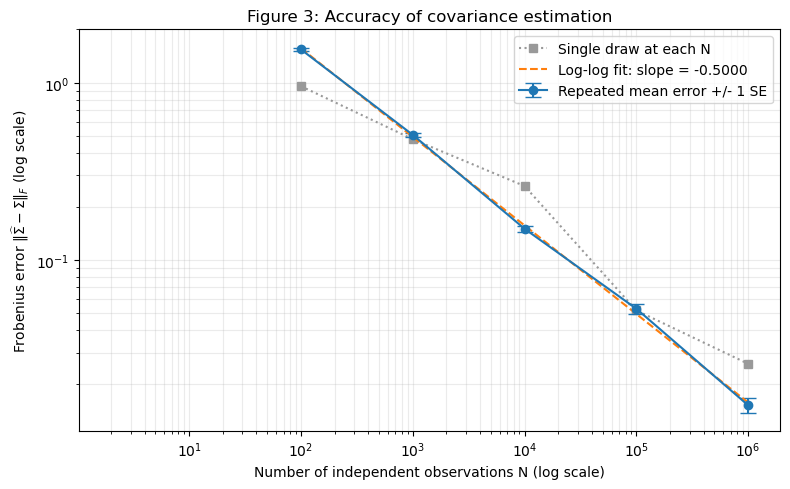

In [12]:
fig3, ax3 = plt.subplots(figsize=(8, 5))

ax3.loglog(
    N_values3,
    single_errors3,
    "s:",
    color="0.6",
    label="Single draw at each N"
)

ax3.errorbar(
    N_values3,
    mean_errors3,
    yerr=se_errors3,
    fmt="o-",
    color="tab:blue",
    capsize=6,
    label="Repeated mean error +/- 1 SE"
)

ax3.loglog(
    N_values3,
    fitted_errors3,
    "--",
    color="tab:orange",
    label=f"Log-log fit: slope = {slope3:.4f}"
)

ax3.set(
    xlabel=(
        "Number of independent observations N "
        "(log scale)"
    ),
    ylabel=(
        r"Frobenius error "
        r"$\|\widehat{\Sigma}-\Sigma\|_F$ "
        r"(log scale)"
    ),
    title="Figure 3: Accuracy of covariance estimation"
)

ax3.grid(True, which="both", alpha=0.25)
ax3.legend()

fig3.tight_layout()
plt.show()

#### Interpretation of Figure 3

The averaged covariance-estimation error decreases approximately as $N^{-1/2}$, as shown by the fitted slope reported in the output and the figure legend.

The printed values of $\sqrt{N}\,\overline{e}_N$ remain roughly constant, providing a second check of this rate. Thus, reducing the error by a factor of two requires approximately four times as many independent observations.

The single-draw curve fluctuates around the averaged curve because each covariance estimate depends on one random dataset. Averaging over independent repetitions makes the convergence trend easier to measure.

The error bars represent one standard error of the averaged Frobenius error. They measure uncertainty in the reported average, rather than the spread of individual covariance estimates.

#### 3.5 Number of covariance parameters

A symmetric $d\times d$ covariance matrix has $d$ diagonal entries and $d(d-1)/2$ distinct off-diagonal entries.

Therefore, the number of free parameters is

$$
p(d)
=
d+\frac{d(d-1)}{2}
=
\frac{d(d+1)}{2}.
$$

For four dimensions,

$$
p(4)=\frac{4(5)}{2}=10.
$$

For one hundred dimensions,

$$
p(100)=\frac{100(101)}{2}=5050.
$$

The number of parameters increases by a factor of

$$
\frac{5050}{10}=505.
$$

As a rough parameter-count planning estimate, assume the squared estimation error scales as $p/N$, with comparable normalization between the two problems. Maintaining the same error then requires the sample size to increase in proportion to $p$:

$$
N_{100}
\approx
10^4\frac{5050}{10}
=
5{,}050{,}000.
$$

This is a heuristic estimate, not a universal requirement for relative Frobenius accuracy.

#### Clarifying the relative-error assumption

Define relative Frobenius error as

$$
\frac{\|\widehat{\Sigma}-\Sigma\|_F}{\|\Sigma\|_F}.
$$

For independent Gaussian observations, the unbiased sample
covariance satisfies

$$
E\left[\|\widehat{\Sigma}-\Sigma\|_F^2\right]
=
\frac{
(\operatorname{tr}\Sigma)^2+\|\Sigma\|_F^2
}{N-1}.
$$

Consequently, the root-mean-square relative error is

$$
\sqrt{
\frac{
1+(\operatorname{tr}\Sigma)^2/\|\Sigma\|_F^2
}{N-1}
}.
$$

Thus, relative accuracy depends on the covariance structure as well as the dimension.

For example, if the 100-dimensional covariance is $I_{100}$, this expression becomes

$$
\sqrt{\frac{101}{N-1}}.
$$

In [13]:
p4_3 = 4*(4+1)//2
p100_3 = 100*(100+1)//2

reference_index3 = int(np.flatnonzero(N_values3 == 10_000)[0])

N_reference3 = int(N_values3[reference_index3])

relative_reference3 = (relative_errors3[reference_index3])

# Rough budget based on the stated parameter-count assumption.
parameter_ratio3 = p100_3/p4_3

N_parameter_budget3 = int(np.ceil(N_reference3*parameter_ratio3))

print(f"Free parameters at d=4: {p4_3}")
print(f"Free parameters at d=100: {p100_3}")

print(
    f"Parameter-count ratio: "
    f"{parameter_ratio3:.1f}"
)

print(
    f"Measured mean relative Frobenius error "
    f"at N={N_reference3:,}: "
    f"{relative_reference3:.6f} "
    f"({100*relative_reference3:.4f}%)"
)

print(
    f"Parameter-count planning heuristic: "
    f"{N_parameter_budget3:,} observations"
)

print("This heuristic assumes squared error scales with parameter count.")
print("The dimension alone does not fix the sample size for relative Frobenius error.")

# Conditional example: a specified 100-D covariance, I_100.
effective_rank3 = (
    np.trace(Sigma3)**2
    / np.linalg.norm(Sigma3, "fro")**2
)

N_identity100_3 = int(
    np.ceil(1 + 101/relative_reference3**2)
)

print(
    f"Effective rank of the 4-D Sigma: "
    f"{effective_rank3:.6f}"
)

print(
    f"For Sigma_100=I_100, matching that error "
    f"as RMS relative error needs about "
    f"{N_identity100_3:,} observations."
)

print("This identity-covariance example and the parameter-count heuristic make different assumptions.")

Free parameters at d=4: 10
Free parameters at d=100: 5050
Parameter-count ratio: 505.0
Measured mean relative Frobenius error at N=10,000: 0.017195 (1.7195%)
Parameter-count planning heuristic: 5,050,000 observations
This heuristic assumes squared error scales with parameter count.
The dimension alone does not fix the sample size for relative Frobenius error.
Effective rank of the 4-D Sigma: 2.578947
For Sigma_100=I_100, matching that error as RMS relative error needs about 341,595 observations.
This identity-covariance example and the parameter-count heuristic make different assumptions.


#### 3.6 Why this matters for a radar array
A radar with 100 array elements must estimate 5050 distinct covariance parameters from a limited number of independent observations, so estimation noise can make interference suppression unreliable.

A designer can use a shrinkage covariance estimator, combining the sample covariance with a structured target to reduce estimation variance when the available data are limited.

## Step 4

## Step 5

## Step 6

## Step 7

## Step 8

## Bonus A

## Bonus B